# Tahap 6 — Evaluasi akhir, perbandingan, dan analisis

Notebook ini **tidak melatih ulang** model. Semua angka dihitung oleh `scripts/06_evaluate_all.py`
(logika di `src/analysis.py`, `src/evaluate.py`, `src/plots.py`) dari model & prediksi tersimpan di `models/`.
Notebook hanya menampilkan tabel dan figur hasilnya, ditambah satu contoh pemanggilan uji DeLong.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
from src.config import load_config
import src.analysis as an, src.evaluate as ev
cfg = load_config(); T, F = cfg.paths.tables, cfg.paths.figures
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
def tampil_md(nama): display(Markdown((T / f"{nama}.md").read_text(encoding="utf-8")))
def gambar(nama, w=900): display(Image(filename=str(F / f"{nama}.png"), width=w))

## a. Tabel final Eksperimen A (dan B sebagai pembanding)
Ambang tiap model = Youden's J yang dipilih di **val**; test dievaluasi sekali. ★ = kriteria seleksi yang ditetapkan sebelumnya (AUC val tertinggi); ▲ = AUC test tertinggi.

In [2]:
tampil_md("06_tabel_final_A")
tampil_md("06_tabel_final_B")

**Eksperimen A** — split test (n = 1624, COVID-19 = 108, prevalensi = 0.067). Ambang = Youden's J yang dipilih di val. ★ = AUC val tertinggi (kriteria seleksi), ▲ = AUC test tertinggi (informasi).

| Model | Accuracy | Balanced Acc | Precision | Recall (Sens.) | Specificity | F1 | ROC-AUC [95% CI] | PR-AUC | AUC val | Ambang | AUC test 3 seed (mean ± std) |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Dummy (stratified) | 0.067 | 0.500 | 0.067 | 1.000 | 0.000 | 0.125 | 0.516 [0.472–0.563] | 0.069 | 0.476 | 0.000 | – |
| Logistic Regression | 0.592 | 0.541 | 0.079 | 0.481 | 0.600 | 0.136 | 0.569 [0.514–0.623] | 0.087 | 0.561 | 0.501 | – |
| SVM (RBF) | 0.554 | 0.554 | 0.081 | 0.556 | 0.553 | 0.142 | 0.576 [0.523–0.629] | 0.088 | 0.574 | 0.249 | – |
| k-NN ▲ | 0.607 | 0.561 | 0.086 | 0.509 | 0.613 | 0.147 | 0.580 [0.525–0.636] | 0.088 | 0.542 | 0.270 | – |
| Random Forest | 0.685 | 0.556 | 0.090 | 0.407 | 0.705 | 0.147 | 0.570 [0.513–0.628] | 0.091 | 0.527 | 0.493 | – |
| XGBoost | 0.446 | 0.531 | 0.073 | 0.630 | 0.433 | 0.131 | 0.572 [0.513–0.629] | 0.097 | 0.546 | 0.320 | – |
| CNN (log-mel) | 0.686 | 0.539 | 0.083 | 0.370 | 0.708 | 0.136 | 0.567 [0.511–0.619] | 0.081 | 0.566 | 0.407 | 0.572 ± 0.006 |
| CNN (MFCC 2D) ★ | 0.587 | 0.530 | 0.076 | 0.463 | 0.596 | 0.130 | 0.544 [0.487–0.601] | 0.086 | 0.580 | 0.362 | 0.579 ± 0.030 |


**Eksperimen B** — split test (n = 152, COVID-19 = 70, prevalensi = 0.461). Ambang = Youden's J yang dipilih di val. ★ = AUC val tertinggi (kriteria seleksi), ▲ = AUC test tertinggi (informasi).

| Model | Accuracy | Balanced Acc | Precision | Recall (Sens.) | Specificity | F1 | ROC-AUC [95% CI] | PR-AUC | AUC val | Ambang |
|---|---|---|---|---|---|---|---|---|---|---|
| Dummy (stratified) | 0.461 | 0.500 | 0.461 | 1.000 | 0.000 | 0.631 | 0.487 [0.417–0.567] | 0.454 | 0.428 | 0.000 |
| Logistic Regression | 0.796 | 0.794 | 0.783 | 0.771 | 0.817 | 0.777 | 0.812 [0.730–0.877] | 0.749 | 0.712 | 0.554 |
| SVM (RBF) ★ ▲ | 0.776 | 0.774 | 0.765 | 0.743 | 0.805 | 0.754 | 0.826 [0.745–0.888] | 0.786 | 0.718 | 0.557 |
| k-NN | 0.697 | 0.692 | 0.688 | 0.629 | 0.756 | 0.657 | 0.776 [0.689–0.848] | 0.675 | 0.648 | 0.539 |
| Random Forest | 0.763 | 0.766 | 0.718 | 0.800 | 0.732 | 0.757 | 0.817 [0.741–0.879] | 0.771 | 0.685 | 0.488 |
| XGBoost | 0.724 | 0.716 | 0.741 | 0.614 | 0.817 | 0.672 | 0.807 [0.726–0.871] | 0.754 | 0.713 | 0.586 |


**Catatan:** menurut kriteria seleksi (AUC val), model terbaik A adalah CNN (MFCC 2D) seed 42, tetapi AUC test-nya
justru terendah (0,544); rata-rata 3 seed 0,579 ± 0,030. Selisih antar-model jauh lebih kecil daripada lebar CI → peringkat
model di A praktis acak. Untuk ML klasik, model terpilih tetap SVM (RBF) (AUC val tertinggi di antara ML).

## b. Uji signifikansi selisih AUC (DeLong + bootstrap berpasangan)

In [3]:
tampil_md("06_uji_signifikansi_auc")

Uji selisih ROC-AUC pada split test yang sama (DeLong; bootstrap berpasangan 2.000×).

| eksperimen | perbandingan | model_1 | model_2 | auc_1 | auc_2 | selisih | DeLong 95% CI | p DeLong | p bootstrap |
|---|---|---|---|---|---|---|---|---|---|
| A | dua teratas (AUC test) | k-NN | SVM (RBF) | 0.580 | 0.576 | 0.004 | [-0.040; +0.047] | 0.867 | 0.857 |
| A | ML terbaik (val) vs CNN log-mel | SVM (RBF) | CNN (log-mel) | 0.576 | 0.567 | 0.009 | [-0.037; +0.055] | 0.696 | 0.719 |
| A | ML terbaik (val) vs CNN MFCC 2D | SVM (RBF) | CNN (MFCC 2D) | 0.576 | 0.544 | 0.032 | [-0.040; +0.104] | 0.388 | 0.402 |
| A | ML terbaik vs baseline | SVM (RBF) | Dummy (stratified) | 0.576 | 0.516 | 0.060 | [-0.015; +0.136] | 0.117 | 0.118 |
| B | dua teratas (AUC test) | SVM (RBF) | Random Forest | 0.826 | 0.817 | 0.009 | [-0.026; +0.044] | 0.616 | 0.625 |
| B | ML terbaik vs baseline | SVM (RBF) | Dummy (stratified) | 0.826 | 0.487 | 0.339 | [+0.229; +0.450] | 0.000 | 0.000 |


In [4]:
# contoh pemanggilan langsung: dua model teratas A pada test
s = an.load_scores("A"); te = s[s.split == "test"]
ev.delong_test(te["label"], te["k-NN"], te["SVM (RBF)"])

{'auc_a': 0.5797236880680152,
 'auc_b': 0.5759979966774161,
 'diff': 0.003725691390599084,
 'se': 0.022213032105627823,
 'z': 0.1677254763277074,
 'p': 0.86679925289739,
 'ci_low': -0.03981185153643145,
 'ci_high': 0.04726323431762962}

## c. Kurva ROC/PR gabungan: ML terbaik vs CNN vs baseline

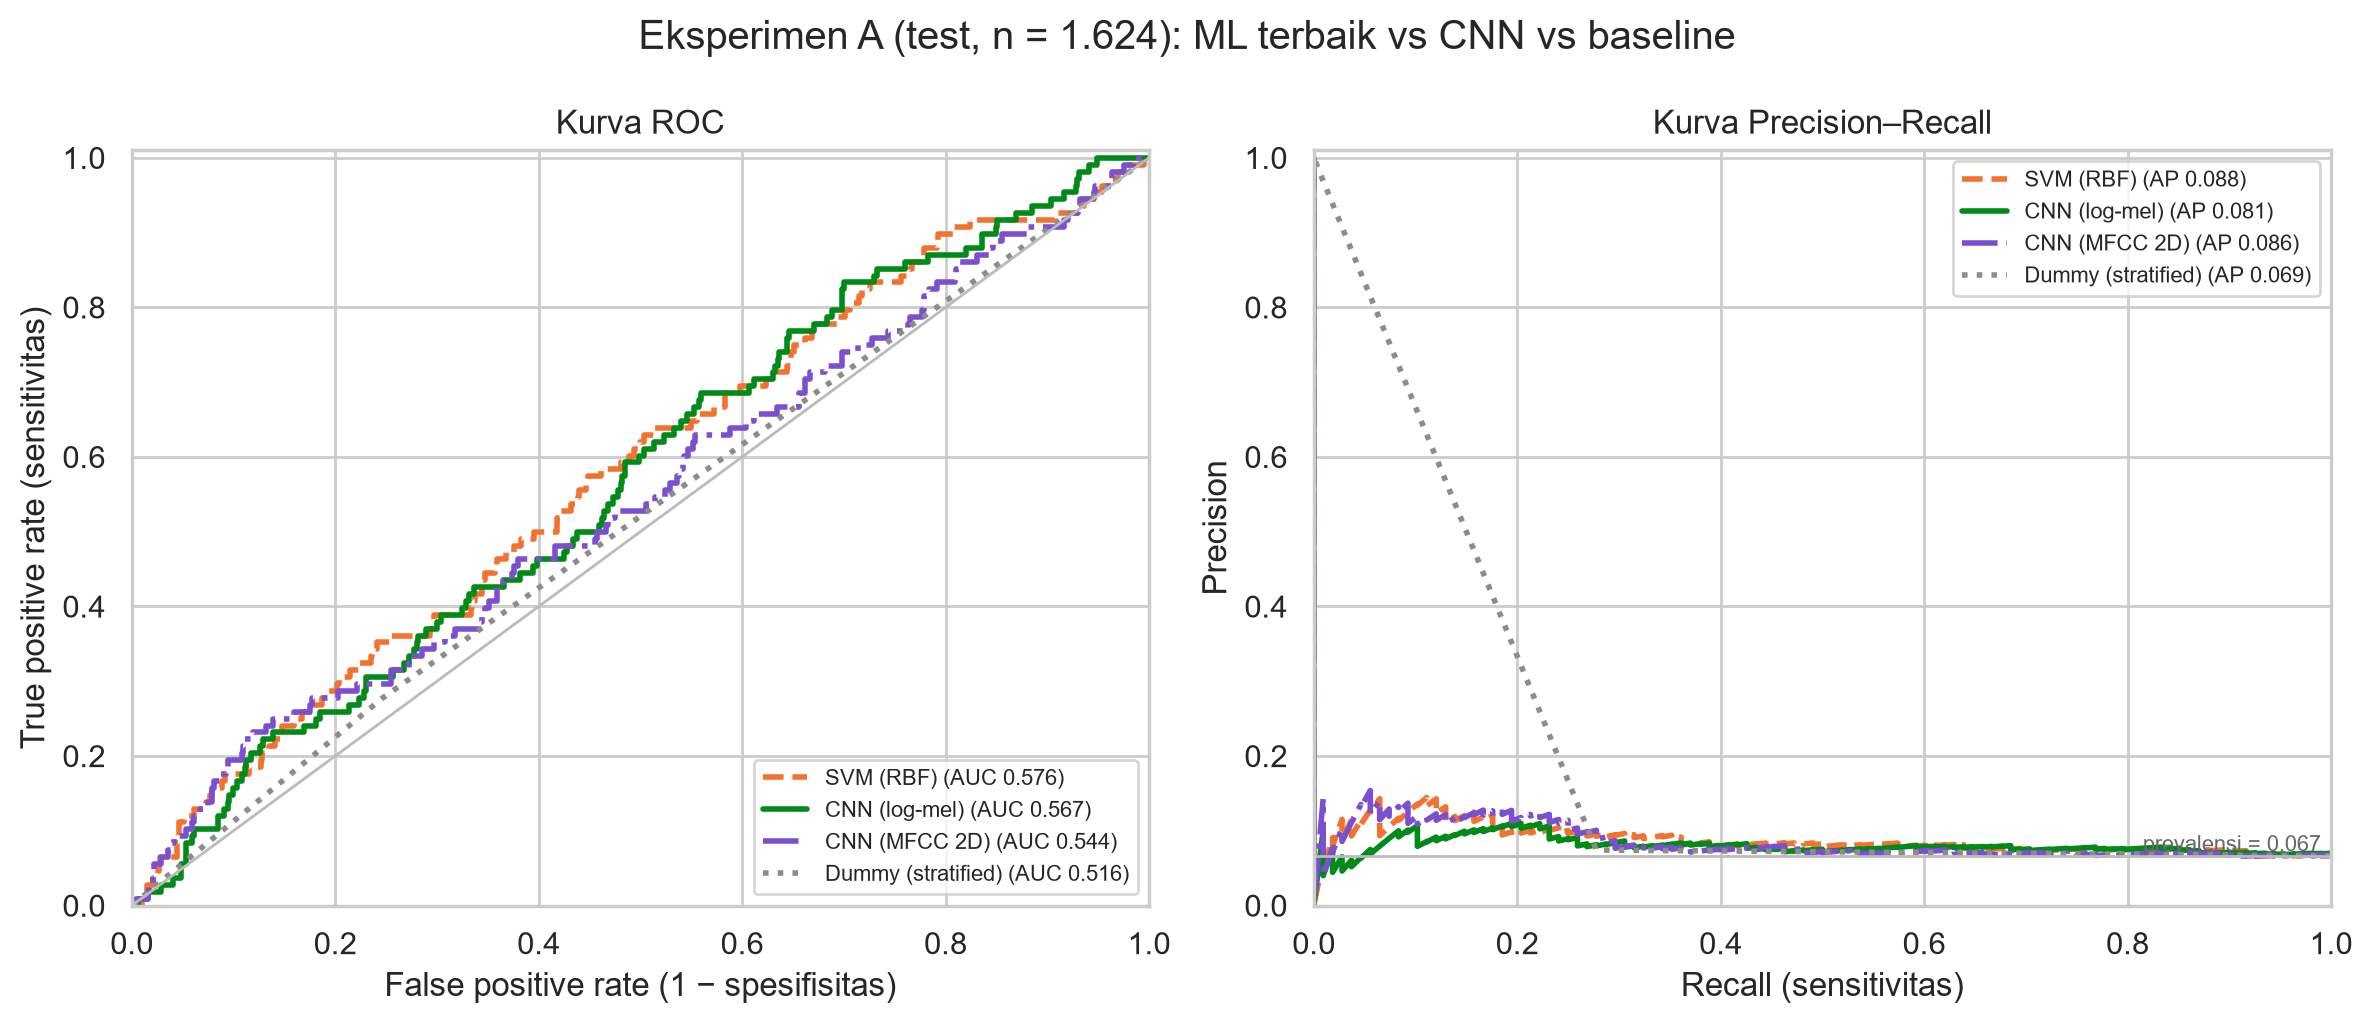

In [5]:
gambar("06_roc_gabungan_A")

## d. Eksperimen B vs A — keandalan label (terinspirasi R4)
1. **Kesepakatan label**: status self-reported vs diagnosis ahli pada rekaman Eksperimen B.
2. **Uji silang**: model A (label self-reported) dan model B (label ahli) dievaluasi pada set yang sama;
   uuid train/val model sumber dibuang (anti *leakage*). S3 = prediksi model A yang identik dinilai dengan dua label.

Rekaman Eksperimen B (n = 1011): status self-reported vs diagnosis ahli (majority vote). Pada 572 rekaman yang keduanya biner: kesepakatan = 0.503, Cohen's κ = 0.000.

| status (self-reported) \ diagnosis ahli | COVID-19 | healthy | Total |
|---|---|---|---|
| COVID-19 | 117 | 155 | 272 |
| healthy | 129 | 171 | 300 |
| symptomatic | 173 | 155 | 328 |
| tidak diisi | 51 | 60 | 111 |
| Total | 470 | 541 | 1011 |


ROC-AUC [CI 95%] uji silang. Kolom = set evaluasi ← sumber label training. S1 n = 102 (51 COVID-19 ahli); S2 n = 1554 (79 COVID-19 self-reported); S3 n = 251 (prediksi identik, dua label). uuid train/val model sumber dibuang dari set evaluasi.

| model | S1: test B (label ahli) ← label ahli (B) | S1: test B (label ahli) ← label self-reported (A) | S2: test A (label self-reported) ← label ahli (B) | S2: test A (label self-reported) ← label self-reported (A) | S3: rekaman B tak terlihat model A — label ahli ← label self-reported (A) | S3: rekaman B tak terlihat model A — label self-reported ← label self-reported (A) |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.874 [0.797–0.946] | 0.682 [0.576–0.784] | 0.559 [0.500–0.619] | 0.580 [0.515–0.645] | 0.596 [0.528–0.669] | 0.509 [0.391–0.616] |
| SVM (RBF) | 0.896 [0.825–0.960] | 0.673 [0.569–0.779] | 0.545 [0.487–0.604] | 0.585 [0.523–0.647] | 0.574 [0.504–0.648] | 0.541 [0.414–0.646] |
| k-NN | 0.840 [0.753–0.917] | 0.611 [0.498–0.721] | 0.574 [0.513–0.638] | 0.576 [0.516–0.638] | 0.517 [0.442–0.595] | 0.551 [0.437–0.660] |
| Random Forest | 0.887 [0.810–0.952] | 0.711 [0.607–0.815] | 0.561 [0.500–0.623] | 0.583 [0.521–0.648] | 0.616 [0.550–0.682] | 0.494 [0.375–0.593] |
| XGBoost | 0.874 [0.796–0.944] | 0.672 [0.569–0.768] | 0.578 [0.518–0.641] | 0.571 [0.505–0.639] | 0.590 [0.524–0.660] | 0.531 [0.420–0.640] |
| CNN (log-mel) | – | 0.653 [0.541–0.763] | – | – | 0.652 [0.588–0.719] | 0.489 [0.376–0.600] |
| CNN (MFCC 2D) | – | 0.489 [0.377–0.612] | – | – | 0.518 [0.450–0.590] | 0.516 [0.403–0.635] |


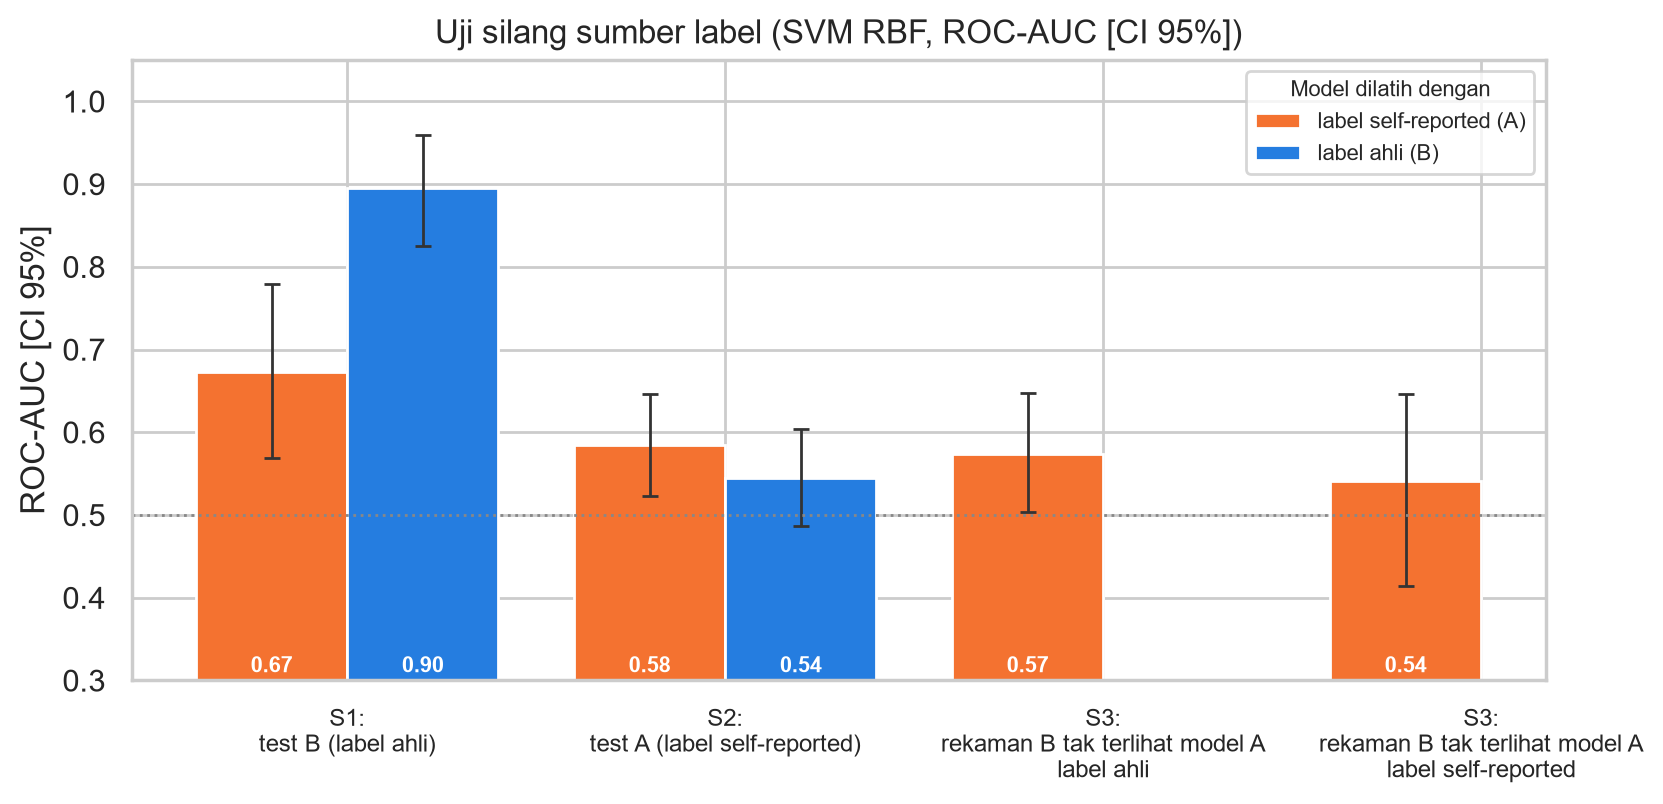

In [6]:
tampil_md("06_kesepakatan_label_B")
tampil_md("06_uji_silang_label")
gambar("06_uji_silang_label")

## e. Analisis error
### e1. Distribusi skor per kelas

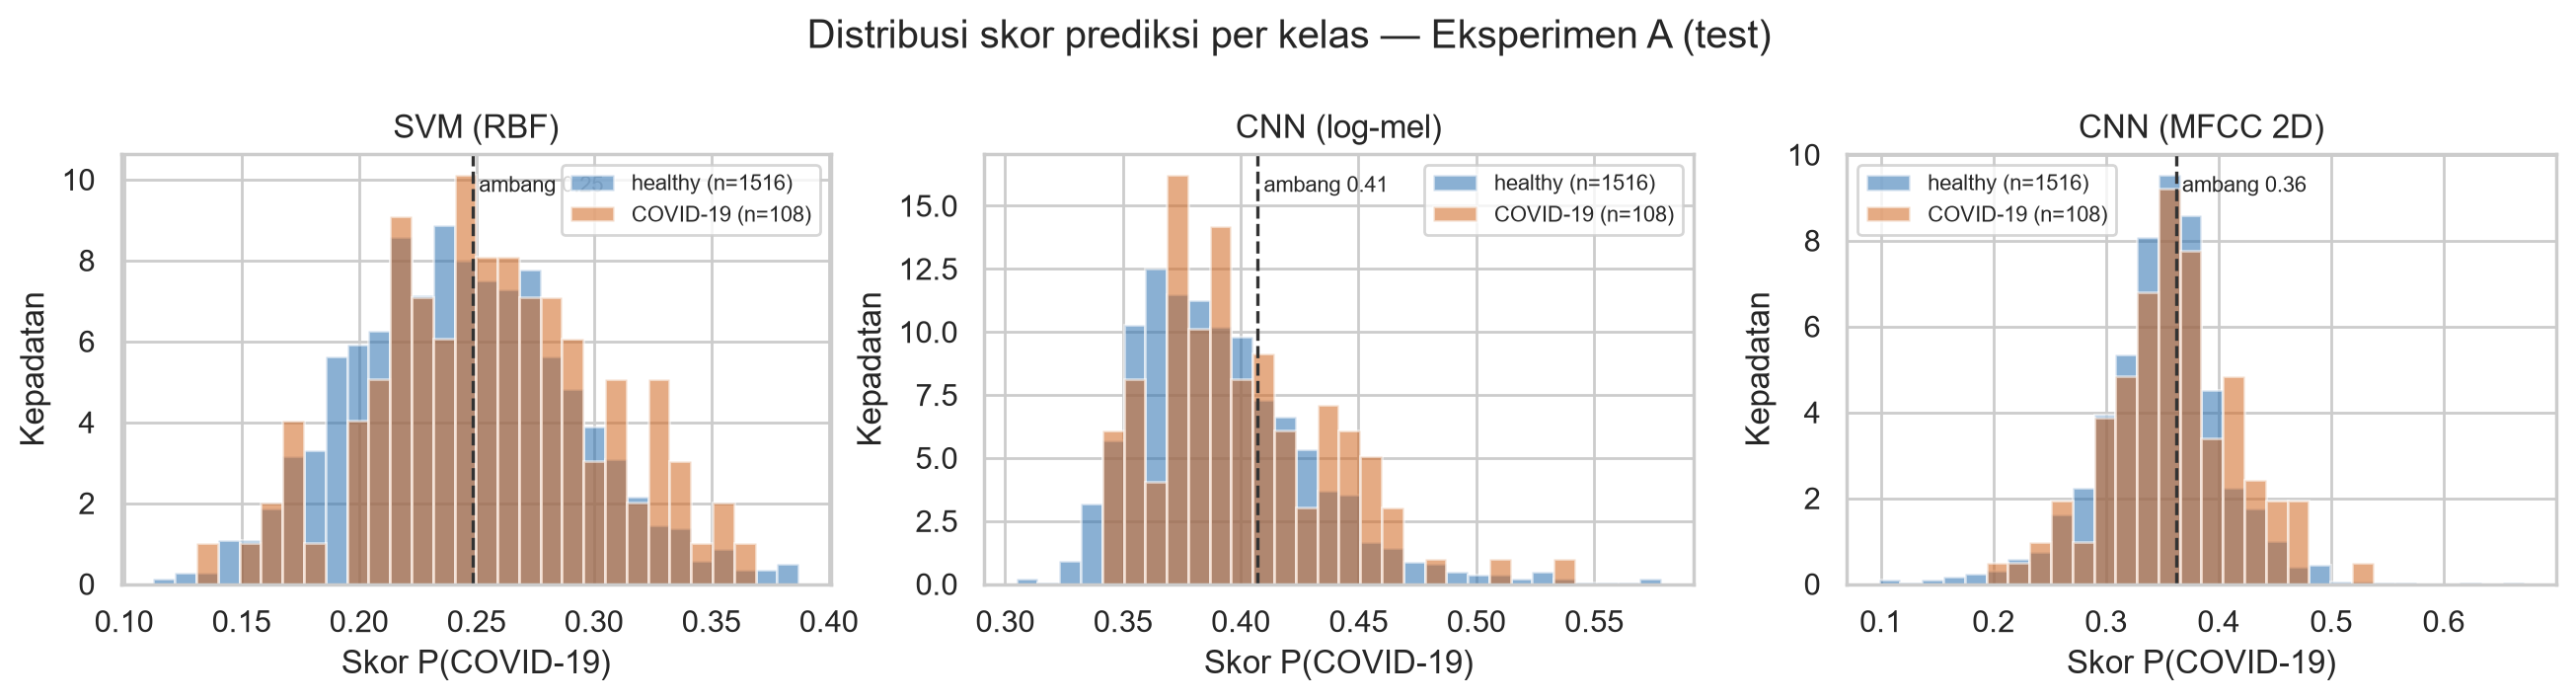

,model,kelas,n,median,p05,p95,ambang,persen_di_atas_ambang
0,SVM (RBF),healthy,1516,0.242,0.170,0.323,0.249,0.447
1,SVM (RBF),COVID-19,108,0.254,0.172,0.338,0.249,0.556
2,CNN (log-mel),healthy,1516,0.386,0.343,0.461,0.407,0.292
3,CNN (log-mel),COVID-19,108,0.391,0.349,0.461,0.407,0.370
4,CNN (MFCC 2D),healthy,1516,0.353,0.256,0.435,0.362,0.404
5,CNN (MFCC 2D),COVID-19,108,0.357,0.261,0.458,0.362,0.463


In [7]:
gambar("06_distribusi_skor_A", 1000)
pd.read_csv(T / "06_distribusi_skor_A.csv").round(3)

### e2. Contoh false positive / false negative paling yakin (SVM RBF)

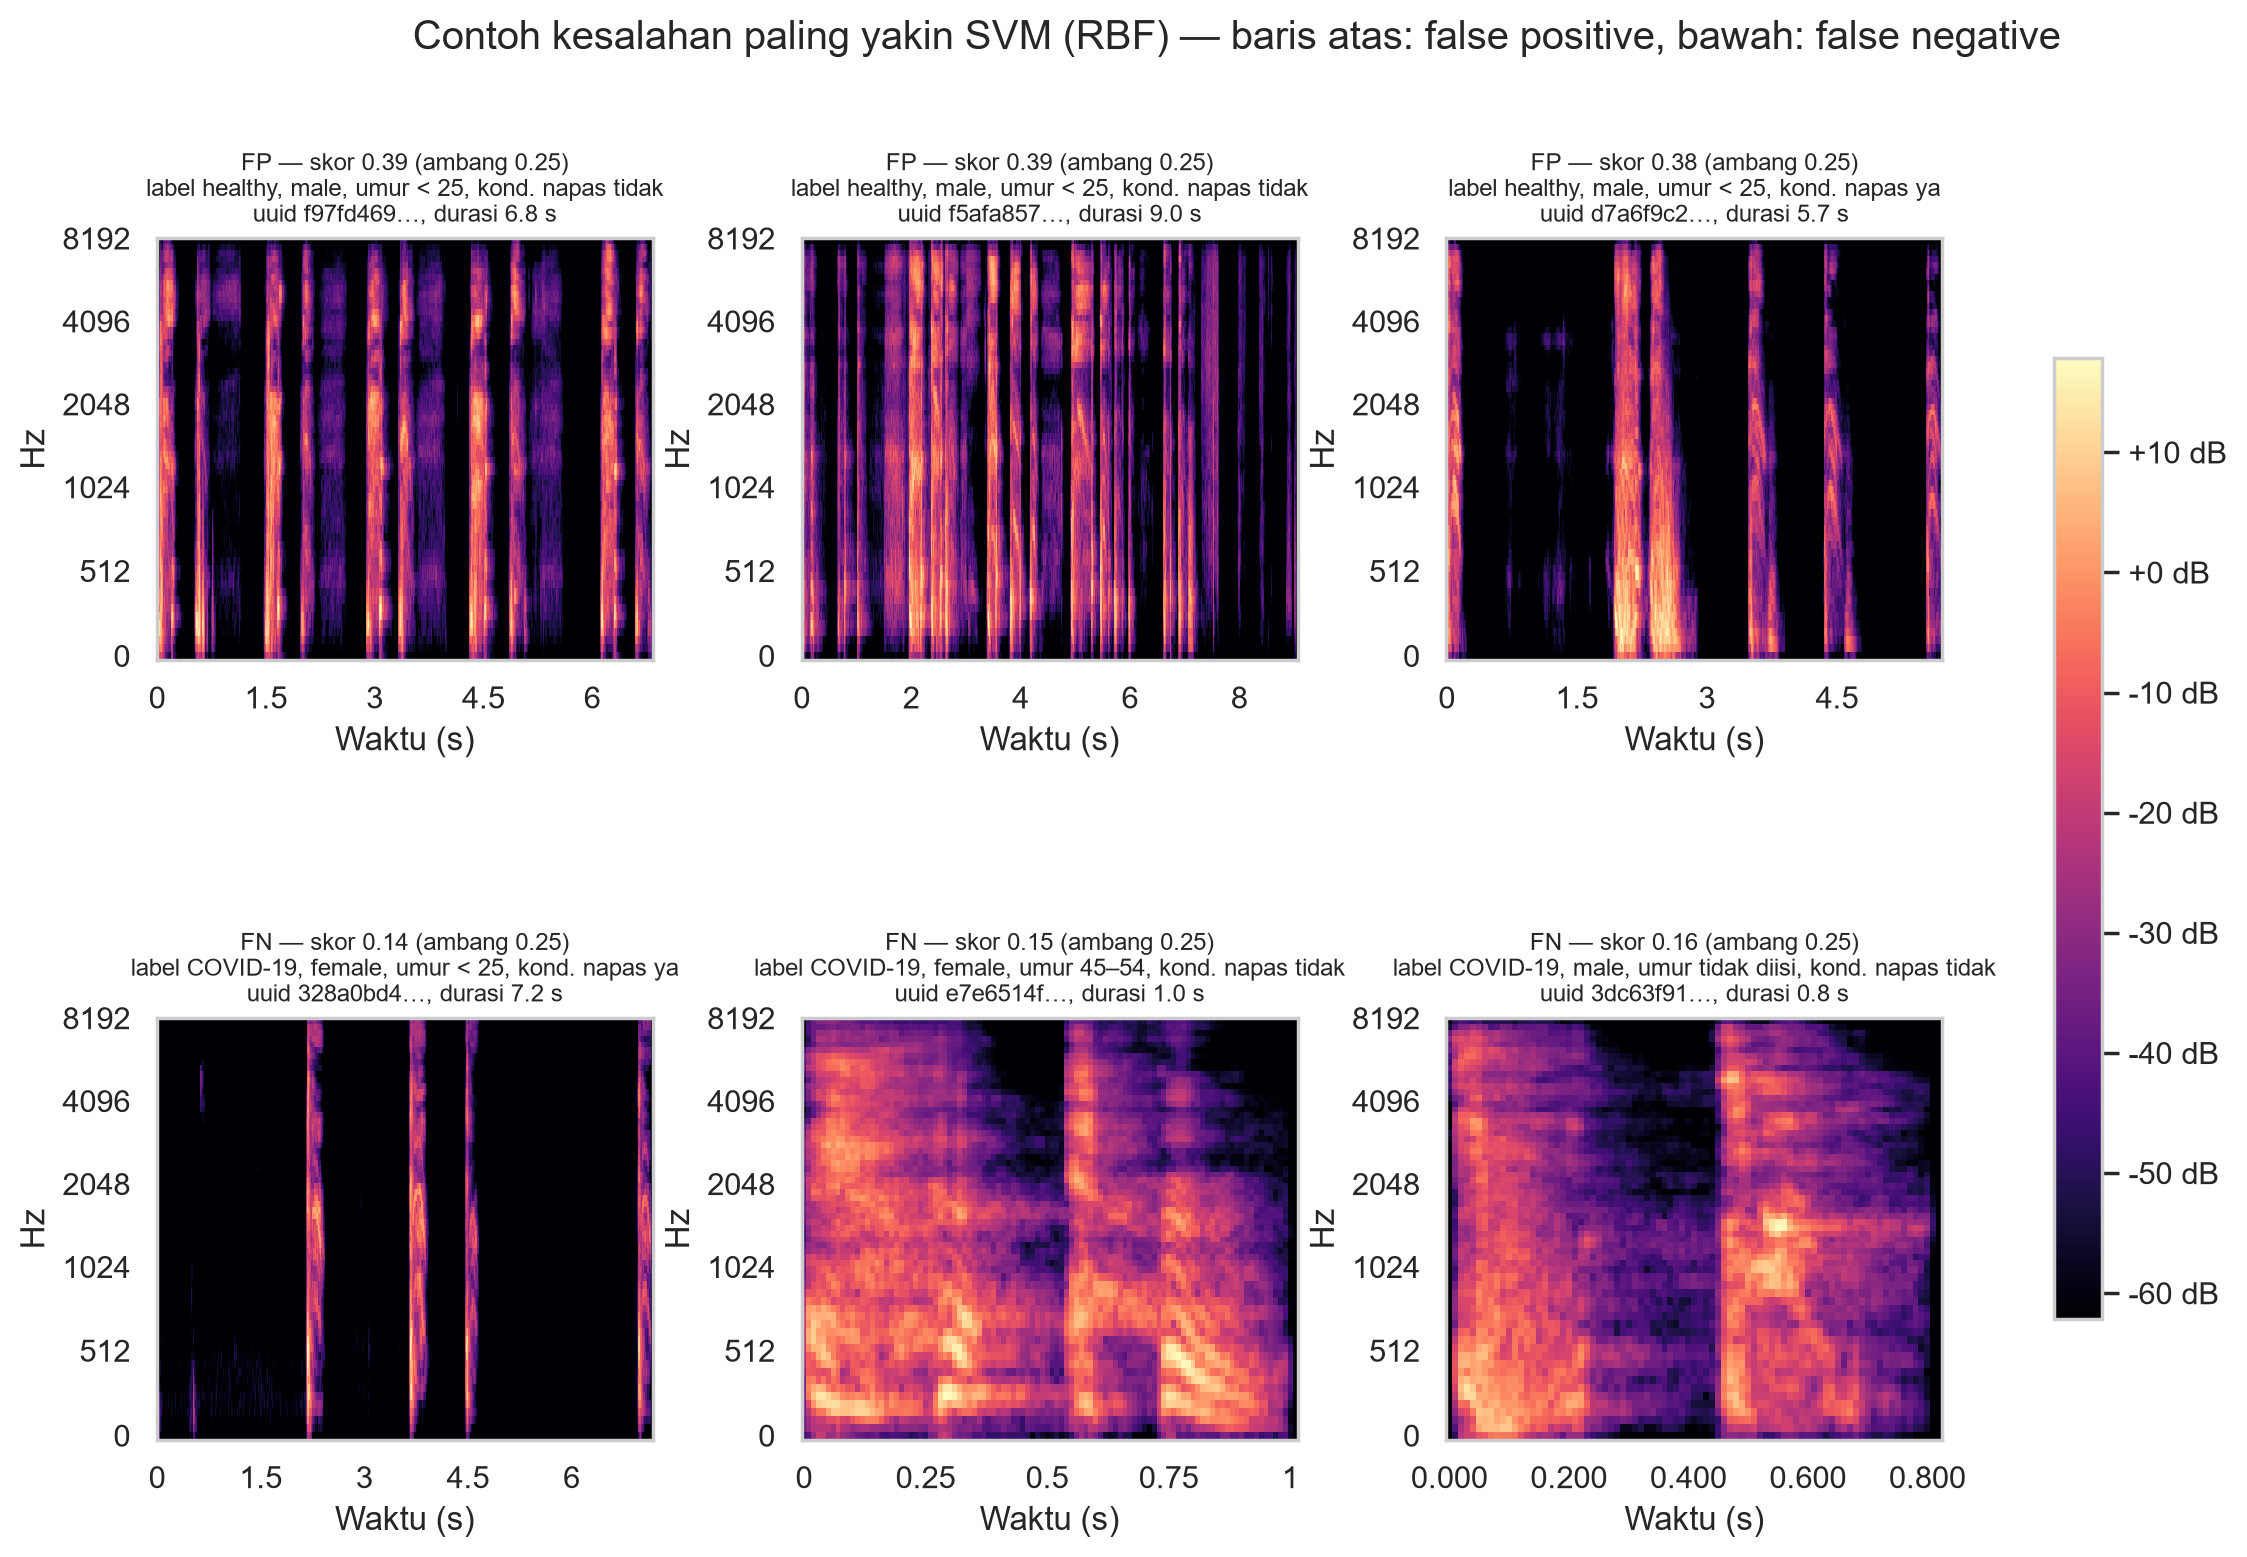

Karakteristik rekaman per jenis keputusan SVM (RBF), Eksperimen A test, ambang 0.249.

| jenis | n | skor_median | durasi_trim_median_s | cough_detected_median | tanpa_segmen_persen | kondisi_napas_ya_persen | demam_ya_persen | laki_laki_persen |
|---|---|---|---|---|---|---|---|---|
| TP | 60 | 0.283 | 4.724 | 0.974 | 0.083 | 0.417 | 0.317 | 0.500 |
| FN | 48 | 0.219 | 3.296 | 0.959 | 0.188 | 0.354 | 0.333 | 0.521 |
| FP | 677 | 0.278 | 5.000 | 0.974 | 0.055 | 0.127 | 0.087 | 0.693 |
| TN | 839 | 0.215 | 3.048 | 0.976 | 0.168 | 0.108 | 0.069 | 0.659 |


,model,kelas,rho_spearman_skor_vs_durasi,auc_durasi_saja
0,SVM (RBF),semua,0.407,0.518
1,SVM (RBF),healthy,0.409,0.518
2,CNN (log-mel),semua,0.606,0.518
3,CNN (log-mel),healthy,0.608,0.518
4,CNN (MFCC 2D),semua,-0.048,0.518
5,CNN (MFCC 2D),healthy,-0.051,0.518


In [8]:
gambar("06_contoh_fp_fn_A", 1000)
tampil_md("06_karakteristik_error_A")
pd.read_csv(T / "06_korelasi_skor_durasi_A.csv").round(3)

### e3. Performa per subgrup (*fairness*)

Performa per subgrup, Eksperimen A test (ambang Youden dari val). AUC hanya bila subgrup punya ≥ 5 positif dan ≥ 5 negatif. Keseluruhan: SVM (RBF) 0.576, CNN (log-mel) 0.567, CNN (MFCC 2D) 0.544

| variabel | subgrup | n | n_pos | prevalensi | AUC SVM [CI 95%] | Sens. SVM | Spes. SVM | AUC CNN (log-mel) | AUC CNN (MFCC 2D) |
|---|---|---|---|---|---|---|---|---|---|
| Demam / nyeri otot | tidak | 1472 | 73 | 0.050 | 0.590 [0.526–0.660] | 0.562 | 0.558 | 0.563 | 0.544 |
| Demam / nyeri otot | ya | 152 | 35 | 0.230 | 0.507 [0.395–0.613] | 0.543 | 0.496 | 0.532 | 0.541 |
| Gender | female | 537 | 50 | 0.093 | 0.585 [0.502–0.670] | 0.540 | 0.579 | 0.568 | 0.572 |
| Gender | male | 1077 | 55 | 0.051 | 0.565 [0.480–0.644] | 0.545 | 0.541 | 0.580 | 0.526 |
| Gender | other | 10 | 3 | 0.300 | – | 1.000 | 0.571 | – | – |
| Kelompok umur | < 25 | 289 | 18 | 0.062 | 0.565 [0.416–0.723] | 0.556 | 0.509 | 0.599 | 0.541 |
| Kelompok umur | 25–34 | 424 | 35 | 0.083 | 0.590 [0.479–0.694] | 0.629 | 0.542 | 0.562 | 0.559 |
| Kelompok umur | 35–44 | 388 | 17 | 0.044 | 0.631 [0.509–0.773] | 0.588 | 0.582 | 0.658 | 0.555 |
| Kelompok umur | 45–54 | 241 | 15 | 0.062 | 0.584 [0.430–0.733] | 0.533 | 0.540 | 0.553 | 0.521 |
| Kelompok umur | ≥ 55 | 195 | 12 | 0.062 | 0.475 [0.315–0.625] | 0.333 | 0.601 | 0.556 | 0.536 |
| Kelompok umur | tidak diisi | 87 | 11 | 0.126 | 0.542 [0.357–0.718] | 0.545 | 0.553 | 0.484 | 0.516 |
| Kondisi pernapasan | tidak | 1405 | 66 | 0.047 | 0.586 [0.515–0.656] | 0.530 | 0.559 | 0.546 | 0.530 |
| Kondisi pernapasan | ya | 219 | 42 | 0.192 | 0.529 [0.439–0.616] | 0.595 | 0.514 | 0.585 | 0.563 |


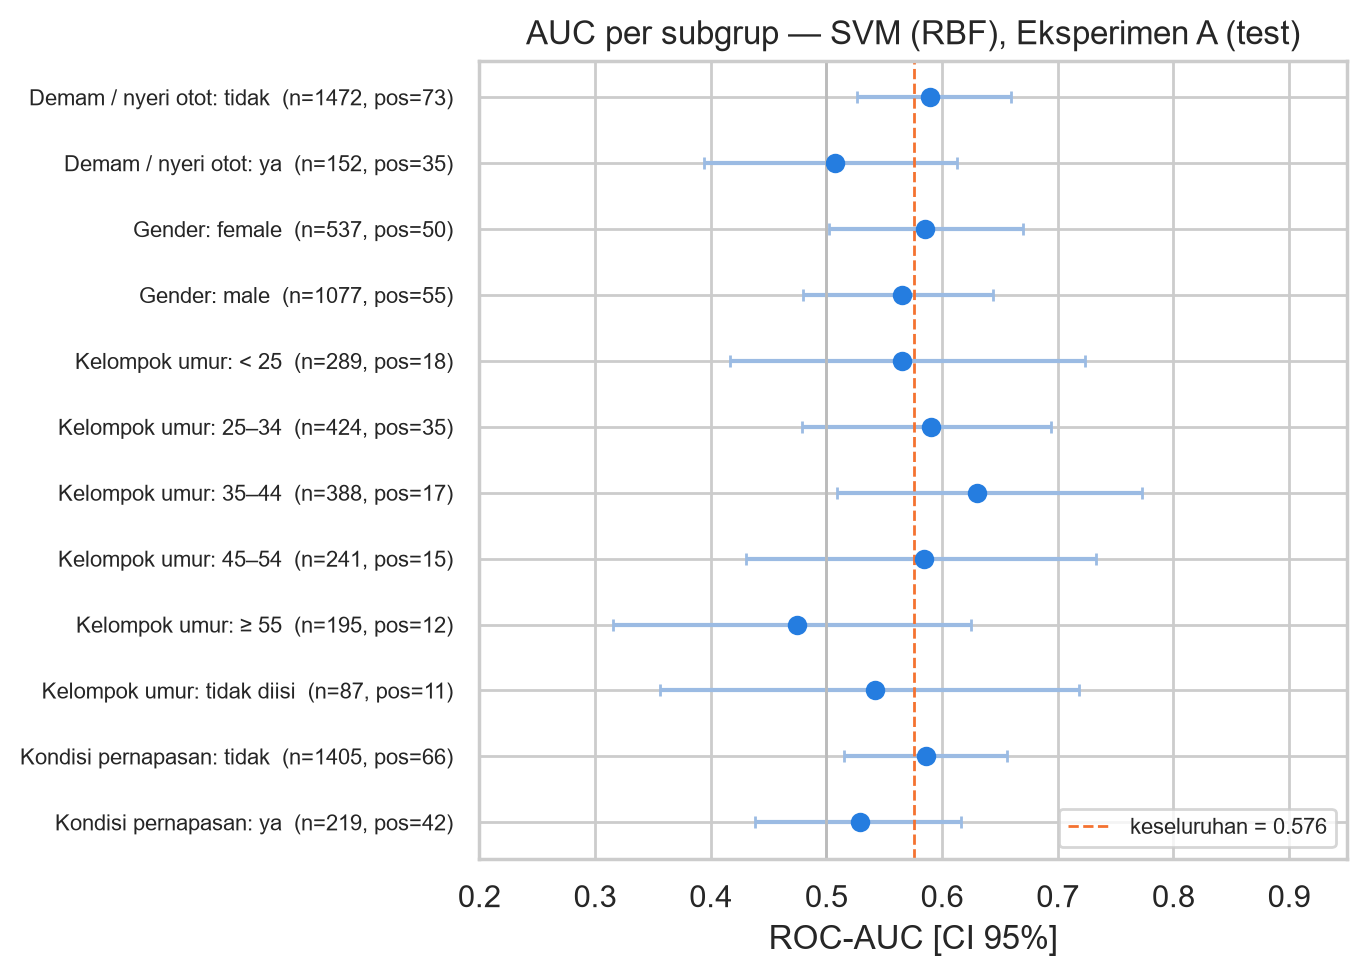

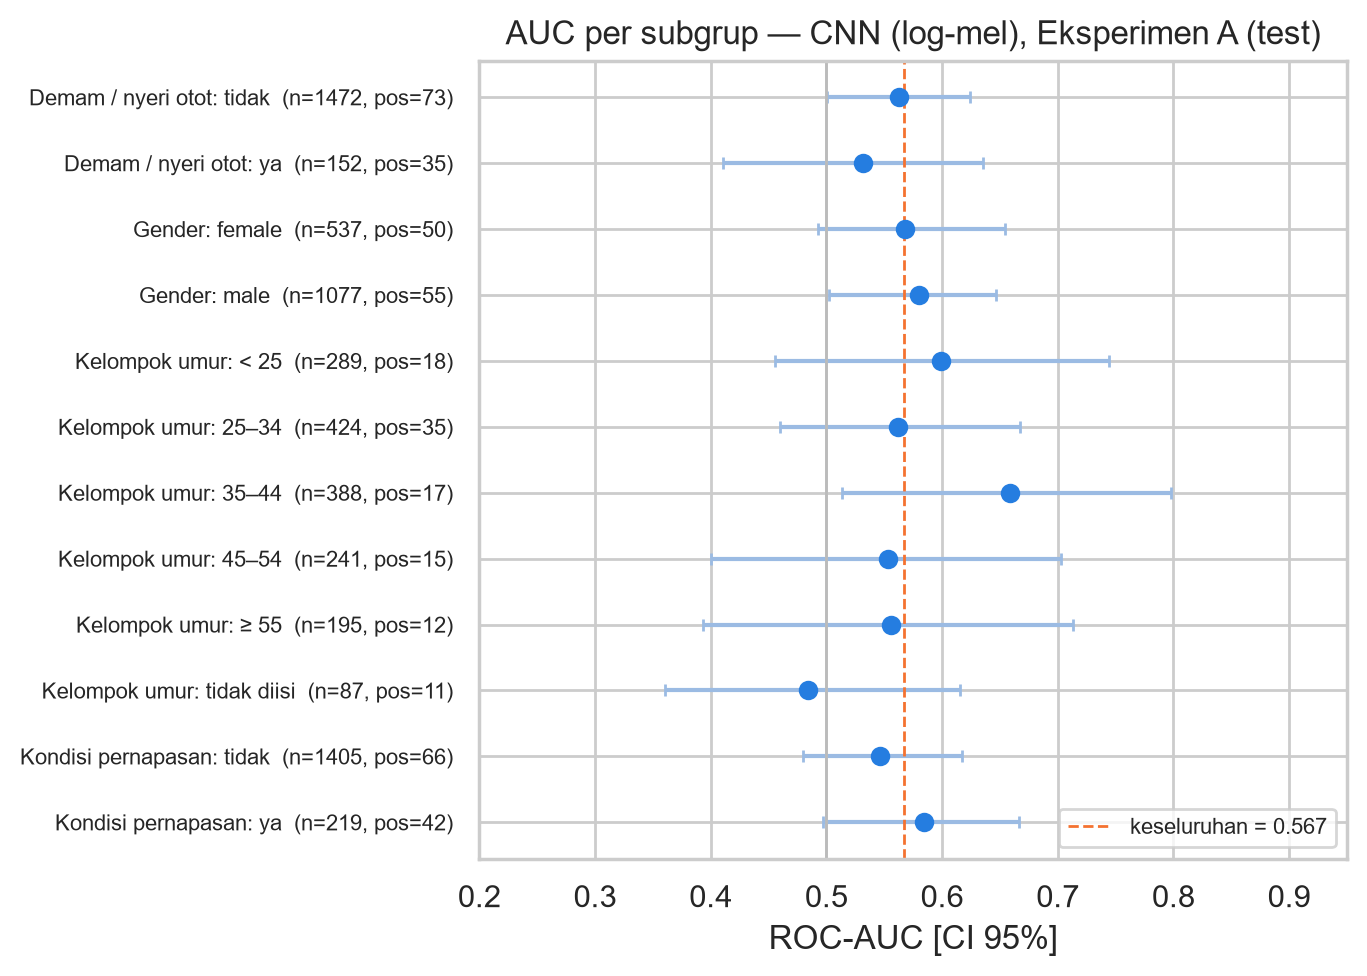

In [9]:
tampil_md("06_subgrup_fairness")
gambar("06_subgrup_svm_A", 700)
gambar("06_subgrup_cnn_logmel_A", 700)

In [10]:
pd.read_csv(T / "06_subgrup_selisih_auc.csv").round(3)

,model,variabel,min,max,selisih
0,CNN (MFCC 2D),Demam / nyeri otot,0.541,0.544,0.003
1,CNN (MFCC 2D),Gender,0.526,0.572,0.046
2,CNN (MFCC 2D),Kelompok umur,0.516,0.559,0.044
3,CNN (MFCC 2D),Kondisi pernapasan,0.530,0.563,0.033
4,CNN (log-mel),Demam / nyeri otot,0.532,0.563,0.031
5,CNN (log-mel),Gender,0.568,0.580,0.012
6,CNN (log-mel),Kelompok umur,0.484,0.658,0.174
7,CNN (log-mel),Kondisi pernapasan,0.546,0.585,0.038
8,SVM (RBF),Demam / nyeri otot,0.507,0.590,0.082
9,SVM (RBF),Gender,0.565,0.585,0.020


## f. Perbandingan dengan literatur

In [11]:
tampil_md("06_perbandingan_literatur")

Perbandingan dengan literatur. Angka literatur dikutip dari PDF di `references/` (nomor halaman jurnal); **[TODO: cek manual]** = angka/klaim yang ambigu di sumber atau belum diverifikasi. R2–R4 tidak memakai COUGHVID → angka **tidak dapat dibandingkan langsung**.

| Referensi | Dataset & data | Label | Fitur & model | Protokol split / augmentasi | Metrik dilaporkan | Catatan perbedaan setting |
|---|---|---|---|---|---|---|
| R0 — Orlandic dkk. (2021), Sci. Data 8:156 | COUGHVID (sumber dataset); >20.000 rekaman batuk crowdsourced (angka v1, dikutip R1 hlm. 145) | self-reported + label ahli (4 pulmonolog) untuk sebagian rekaman | Detektor batuk (XGBoost) untuk `cough_detected`; bukan klasifikator COVID-19 utama | lihat paper | lihat paper [TODO: cek manual — PDF R0 tidak ada di references/] | Paper dataset; bukan benchmark diagnosis. Angka spesifik belum diverifikasi. |
| R2 — Lella & Pja (2022), Alexandria Eng. J. 61:1319–1334 | Cambridge 'COVID-19 Sounds' (batuk, napas, suara); ±1.539 track (hlm. 1328), ±300 pengguna positif (hlm. 1322) — BUKAN COUGHVID | status dari aplikasi (kemungkinan self-reported) [TODO: cek manual] | De-noising autoencoder + GFCC + IMFCC (multi-feature channel) → DCNN, softmax | 5 folder / k-fold, tidak per subjek; augmentasi (time stretch, pitch shift, DRC, noise; MUDA) — urutan augmentasi vs split tidak dinyatakan | Accuracy 95,45% / F1 96,96% (napas+batuk+suara, Tabel 2 hlm. 1328); batuk saja accuracy 93,12% / F1 94,13% (Tabel 4 hlm. 1332) [TODO: cek manual — label tugas di Tabel 2–5 tidak konsisten]. Tidak melaporkan AUC | Dataset, modalitas, dan metrik berbeda; augmentasi berpotensi sebelum split (risiko leakage). |
| R3 — Kranthi Kumar & Alphonse (2022), Eur. Phys. J. ST 231:3329–3346 | Cambridge 'COVID-19 Sounds' (batuk, napas, suara); 1.541 file (hlm. 3336) vs ±13.000 sampel (hlm. 3338) [TODO: cek manual] — BUKAN COUGHVID | tidak dinyatakan (mewarisi label aplikasi) | MFCC / E-GFCC / M-MFCC → CNN ringan (receptive field 1×12, 5 layer, BN) | 5 folder; pembagian 10%/10%/80% (kalimat hlm. 3338 kontradiktif); tidak per subjek; augmentasi disebut, urutan terhadap split tidak dinyatakan | Accuracy 91,32% / F1 92,48% (M-MFCC, 1×12; Tabel 1 hlm. 3341); batuk+napas+suara accuracy 92,32% / F1 93,48% (Tabel 3 hlm. 3342). Tidak melaporkan AUC | Dataset/modalitas berbeda; hanya accuracy & F1 (bias pada data seimbang); jumlah data tidak jelas. |
| R4 — Xiong dkk. (2022), Sci. Rep. 12:21990 | Rekaman batuk call-centre MedInGroup: 698 rekaman (1 per subjek; hlm. 3) — BUKAN COUGHVID | PCR-confirmed (terverifikasi) vs patient-reported (tidak terverifikasi); non-COVID self-reported | openSMILE 6.373 fitur + seleksi ElasticNet → LR, LDA, RF, XGB, DNN, CNN-RNN, CA-CNN | per subjek; train 274 subjek, test 63 subjek berlabel PCR (20 COVID / 43 non); diulang 5×; tanpa augmentasi | RF AUC 0,83 (label PCR) vs 0,79 (label self-reported); CA-CNN AUC 0,80 vs 0,47 (Tabel 2 hlm. 5) [TODO: cek manual — teks hlm. 4 menyebut selisih 0,02–0,10] | Setting paling mirip dengan kita (AUC, data tak seimbang, isu label); test berlabel PCR, kita tidak punya PCR. |
| Penelitian ini | COUGHVID v3, batuk saja, cough_detected ≥ 0,8. A: 10.852 rekaman (720 COVID-19); B: 1.013 rekaman berlabel ahli (470 COVID-19) | A: self-reported; B: majority vote diagnosis pulmonolog | 315 fitur tabular (MFCC±Δ, GFCC, spektral, pitch, RMS/ZCR) → LR/SVM/k-NN/RF/XGBoost; log-mel & MFCC 2D → LightCNN (97 ribu parameter) | split per uuid 70/15/15 SEBELUM undersampling/SMOTE/augmentasi/scaling; tuning di train, ambang di val, test sekali; tanpa ID subjek | A: AUC test SVM 0.576 [0.523–0.629], CNN log-mel 0.567, CNN MFCC 2D 0.544 (3 seed: 0.579 ± 0.030); PR-AUC ≈ 0,09 (prevalensi 0,067); accuracy SVM 0.554. B: AUC test SVM 0.826 [0.745–0.888] | Test dengan prevalensi alami (1:14); accuracy tidak informatif → AUC/PR-AUC utama. |


Ringkasan naratif: `reports/ringkasan_hasil.md`; daftar figur & tabel: `reports/daftar_figur_tabel.md`.